Goal : Getting the differential peaks of H3K4me3 with  spikein for all D2 comparaison

In [ ]:
library(data.table)
library(DiffBind)
library(TxDb.Mmusculus.UCSC.mm10.knownGene)
library(ChIPseeker)
library(org.Mm.eg.db)
library(Rsamtools)
library(tidyverse)
library(dplyr)


In [2]:
bam_files <- list.files(
  path = "/data/bams",
  pattern = "*_CnT_H3K4me3.*\\.bam$",
  full.names = TRUE
)

bam_files

[1] "/data/bams/E14_2iD0_TKO_H3_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_073_trimV5_mm10.bam"  
 [2] "/data/bams/E14_2iD0_TKO_H3_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_077_trimV5_mm10.bam"  
 [3] "/data/bams/E14_2iD0_TKO_K4M_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_074_trimV5_mm10.bam" 
 [4] "/data/bams/E14_2iD0_TKO_K4M_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_078_trimV5_mm10.bam" 
 [5] "/data/bams/E14_2iD0_WT_H3_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_071_trimV5_mm10.bam"   
 [6] "/data/bams/E14_2iD0_WT_H3_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_075_trimV5_mm10.bam"   
 [7] "/data/bams/E14_2iD0_WT_K4M_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_072_trimV5_mm10.bam"  
 [8] "/data/bams/E14_2iD0_WT_K4M_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_076_trimV5_mm10.bam"  
 [9] "/data/bams/E14_EpiD2_TKO_H3_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_081_trimV5_mm10.bam" 
[10] "/data/bams/E14_EpiD2_TKO_H3_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_085_trimV5_mm10.bam" 
[11] "/data/bams/E14_EpiD2_TKO_K4M_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_082_trimV5_mm10.bam"
[12] "/data/bams/E14_EpiD2_TKO_K4M_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_086_trimV5_mm10.bam"
[13] "/data/bams/E14_EpiD2_WT_H3_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_079_trimV5_mm10.bam"  
[14] "/data/bams/E14_EpiD2_WT_H3_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_083_trimV5_mm10.bam"  
[15] "/data/bams/E14_EpiD2_WT_K4M_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_080_trimV5_mm10.bam" 
[16] "/data/bams/E14_EpiD2_WT_K4M_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_084_trimV5_mm10.bam"

In [4]:
peak_files <- list.files(
  path = "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results",
    pattern = "*_CnT_H3K4me3.*\\.broadPeak$",
  full.names = TRUE
)
peak_files

[1] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_2iD0_TKO_H3_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_073_trimV5_mm10.filtered.broadPeak"  
 [2] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_2iD0_TKO_H3_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_077_trimV5_mm10.filtered.broadPeak"  
 [3] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_2iD0_TKO_K4M_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_074_trimV5_mm10.filtered.broadPeak" 
 [4] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_2iD0_TKO_K4M_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_078_trimV5_mm10.filtered.broadPeak" 
 [5] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_2iD0_WT_H3_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_071_trimV5_mm10.filtered.broadPeak"   
 [6] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_2iD0_WT_H3_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_075_trimV5_mm10.filtered.broadPeak"   
 [7] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_2iD0_WT_K4M_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_072_trimV5_mm10.filtered.broadPeak"  
 [8] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_2iD0_WT_K4M_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_076_trimV5_mm10.filtered.broadPeak"  
 [9] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_EpiD2_TKO_H3_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_081_trimV5_mm10.filtered.broadPeak" 
[10] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_EpiD2_TKO_H3_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_085_trimV5_mm10.filtered.broadPeak" 
[11] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_EpiD2_TKO_K4M_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_082_trimV5_mm10.filtered.broadPeak"
[12] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_EpiD2_TKO_K4M_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_086_trimV5_mm10.filtered.broadPeak"
[13] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_EpiD2_WT_H3_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_079_trimV5_mm10.filtered.broadPeak"  
[14] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_EpiD2_WT_H3_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_083_trimV5_mm10.filtered.broadPeak"  
[15] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_EpiD2_WT_K4M_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_080_trimV5_mm10.filtered.broadPeak" 
[16] "/scratch/Narjesse/scripts/H3K4me3/peakcalling/results/E14_EpiD2_WT_K4M_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_084_trimV5_mm10.filtered.broadPeak"

In [ ]:
#list of bam file containing the spike in
spike_files <- c("/scratch/Narjesse/scripts/H3K4me3/alignement/AD_073_MKDL250006873-1A_22VTYVLT4_L7_NH/AD_073_MKDL250006873-1A_22VTYVLT4_L7_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_077_MKDL250006877-1A_22VTYVLT4_L8_NH/AD_077_MKDL250006877-1A_22VTYVLT4_L8_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_074_MKDL250006874-1A_22VTYVLT4_L7_NH/AD_074_MKDL250006874-1A_22VTYVLT4_L7_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_078_MKDL250006878-1A_22VTYVLT4_L8_NH/AD_078_MKDL250006878-1A_22VTYVLT4_L8_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_071_MKDL250006871-1A_22VTYVLT4_L7_NH/AD_071_MKDL250006871-1A_22VTYVLT4_L7_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_075_MKDL250006875-1A_22VTYVLT4_L8_NH/AD_075_MKDL250006875-1A_22VTYVLT4_L8_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_072_MKDL250006872-1A_22VTYVLT4_L7_NH/AD_072_MKDL250006872-1A_22VTYVLT4_L7_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_076_MKDL250006876-1A_22VTYVLT4_L7_NH/AD_076_MKDL250006876-1A_22VTYVLT4_L7_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_081_MKDL250006881-1A_22VTYVLT4_L8_NH/AD_081_MKDL250006881-1A_22VTYVLT4_L8_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_085_MKDL250006885-1A_22VTYVLT4_L8_NH/AD_085_MKDL250006885-1A_22VTYVLT4_L8_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_082_MKDL250006882-1A_22VTYVLT4_L8_NH/AD_082_MKDL250006882-1A_22VTYVLT4_L8_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_086_MKDL250006886-1A_22VTYVLT4_L8_NH/AD_086_MKDL250006886-1A_22VTYVLT4_L8_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_079_MKDL250006879-1A_22VTYVLT4_L8_NH/AD_079_MKDL250006879-1A_22VTYVLT4_L8_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_083_MKDL250006883-1A_22VTYVLT4_L8_NH/AD_083_MKDL250006883-1A_22VTYVLT4_L8_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_080_MKDL250006880-1A_22VTYVLT4_L8_NH/AD_080_MKDL250006880-1A_22VTYVLT4_L8_NH_raw_sorted.bam",
                "/scratch/Narjesse/scripts/H3K4me3/alignement/AD_084_MKDL250006884-1A_22VTYVLT4_L8_NH/AD_084_MKDL250006884-1A_22VTYVLT4_L8_NH_raw_sorted.bam")



In [ ]:
#creating the sample sheet
sample_names <- c("D0_TKO_H3_1","D0_TKO_H3_2","D0_TKO_K4M_1","D0_TKO_K4M_2","D0_WT_H3_1", "D0_WT_H3_2","D0_WT_K4M_1","D0_WT_K4M_2","D2_TKO_H3_1","D2_TKO_H3_2","D2_TKO_K4M_1", "D2_TKO_K4M_2","D2_WT_H3_1", "D2_WT_H3_2","D2_WT_K4M_1","D2_WT_K4M_2")

treatment <- c("D0_TKO_H3","D0_TKO_H3","D0_TKO_K4M","D0_TKO_K4M","D0_WT_H3", "D0_WT_H3","D0_WT_K4M","D0_WT_K4M","D2_TKO_H3","D2_TKO_H3","D2_TKO_K4M","D2_TKO_K4M","D2_WT_H3", "D2_WT_H3","D2_WT_K4M","D2_WT_K4M")

sample_sheet <- data.frame(
  SampleID = sample_names,       
  Condition = treatment,         
  bamReads = bam_files,          
  Peaks = peak_files,            
  PeakCaller = "broad",
  Spikein = spike_files,
  stringsAsFactors = FALSE
)
 write.csv(sample_sheet, "H3K4me3_spikein_seq_sample_sheet.csv", row.names = FALSE)

In [7]:
atac_db <- dba(sampleSheet = sample_sheet, scoreCol=5)
dba.show(atac_db)

D0_TKO_H3_1   D0_TKO_H3  NA broad

D0_TKO_H3_2   D0_TKO_H3  NA broad

D0_TKO_K4M_1   D0_TKO_K4M  NA broad

D0_TKO_K4M_2   D0_TKO_K4M  NA broad

D0_WT_H3_1   D0_WT_H3  NA broad

D0_WT_H3_2   D0_WT_H3  NA broad

D0_WT_K4M_1   D0_WT_K4M  NA broad

D0_WT_K4M_2   D0_WT_K4M  NA broad

D2_TKO_H3_1   D2_TKO_H3  NA broad

D2_TKO_H3_2   D2_TKO_H3  NA broad

D2_TKO_K4M_1   D2_TKO_K4M  NA broad

D2_TKO_K4M_2   D2_TKO_K4M  NA broad

D2_WT_H3_1   D2_WT_H3  NA broad

D2_WT_H3_2   D2_WT_H3  NA broad

D2_WT_K4M_1   D2_WT_K4M  NA broad

D2_WT_K4M_2   D2_WT_K4M  NA broad



,ID,Condition,Caller,Intervals
,<chr>,<chr>,<chr>,<dbl>
1,D0_TKO_H3_1,D0_TKO_H3,broad,26456
2,D0_TKO_H3_2,D0_TKO_H3,broad,40675
3,D0_TKO_K4M_1,D0_TKO_K4M,broad,21049
4,D0_TKO_K4M_2,D0_TKO_K4M,broad,28132
5,D0_WT_H3_1,D0_WT_H3,broad,28966
6,D0_WT_H3_2,D0_WT_H3,broad,42320
7,D0_WT_K4M_1,D0_WT_K4M,broad,19298
8,D0_WT_K4M_2,D0_WT_K4M,broad,29148
9,D2_TKO_H3_1,D2_TKO_H3,broad,33697


In [ ]:
# get the count matrix
atac_db<-dba.count(atac_db, summits = FALSE, bParallel=FALSE)
save(atac_db, file = "H3K4me3_spikein_db_full_counts.RData")

Sample: /data/bams/E14_2iD0_TKO_H3_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_073_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_TKO_H3_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_077_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_TKO_K4M_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_074_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_TKO_K4M_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_078_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_WT_H3_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_071_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_WT_H3_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD_075_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_WT_K4M_doxPos_rep1_CnT_H3K4me3_SpikeIn_AD_072_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_WT_K4M_doxPos_rep2_CnT_H3K4me3_SpikeIn_AD

In [3]:
load("H3K4me3_spikein_db_full_counts.RData")

In [4]:
dba.show(atac_db)
counts <- dba.peakset(atac_db, bRetrieve = TRUE)
head(counts)

,ID,Condition,Caller,Intervals,Reads,FRiP
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,D0_TKO_H3_1,D0_TKO_H3,counts,43954,5828313,0.61
2,D0_TKO_H3_2,D0_TKO_H3,counts,43954,22595537,0.62
3,D0_TKO_K4M_1,D0_TKO_K4M,counts,43954,3798717,0.54
4,D0_TKO_K4M_2,D0_TKO_K4M,counts,43954,18981602,0.71
5,D0_WT_H3_1,D0_WT_H3,counts,43954,6986185,0.68
6,D0_WT_H3_2,D0_WT_H3,counts,43954,19637689,0.76
7,D0_WT_K4M_1,D0_WT_K4M,counts,43954,3193558,0.62
8,D0_WT_K4M_2,D0_WT_K4M,counts,43954,17753691,0.75
9,D2_TKO_H3_1,D2_TKO_H3,counts,43954,11190673,0.70


GRanges object with 6 ranges and 16 metadata columns:
    seqnames          ranges strand | D0_TKO_H3_1 D0_TKO_H3_2 D0_TKO_K4M_1
       <Rle>       <IRanges>  <Rle> |   <numeric>   <numeric>    <numeric>
  1     chr1 3531501-3533326      * |     17.4800     5.79705      3.83134
  2     chr1 3549063-3550114      * |     22.4743     5.79705      0.00000
  3     chr1 3670436-3672636      * |    172.3033   166.82626     88.12075
  4     chr1 4491799-4493768      * |    519.4070   618.35216    406.12174
  5     chr1 4496493-4497633      * |      9.9886    44.44406     11.49401
  6     chr1 4571183-4572256      * |     14.9829   123.67043     19.15669
    D0_TKO_K4M_2 D0_WT_H3_1 D0_WT_H3_2 D0_WT_K4M_1 D0_WT_K4M_2 D2_TKO_H3_1
       <numeric>  <numeric>  <numeric>   <numeric>   <numeric>   <numeric>
  1      6.90076    2.08328    4.44681      9.1147    0.819783     24.7107
  2      2.30025    2.08328    5.92907      0.0000    4.098913     22.1096
  3    184.78703  181.24519  277.18424    118.

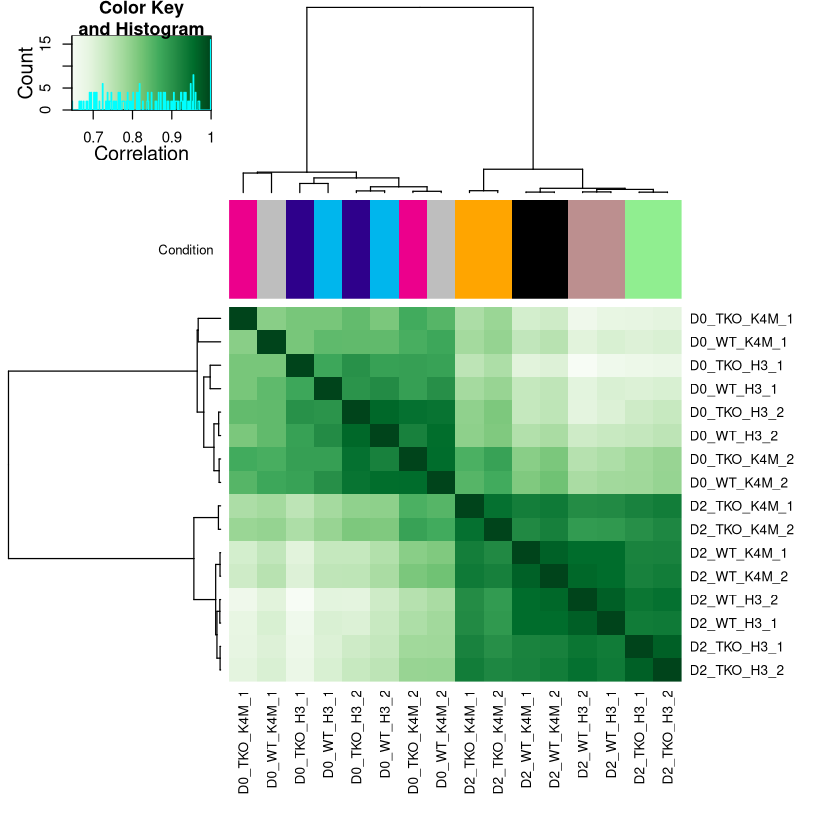

In [5]:
dba.plotHeatmap(atac_db)

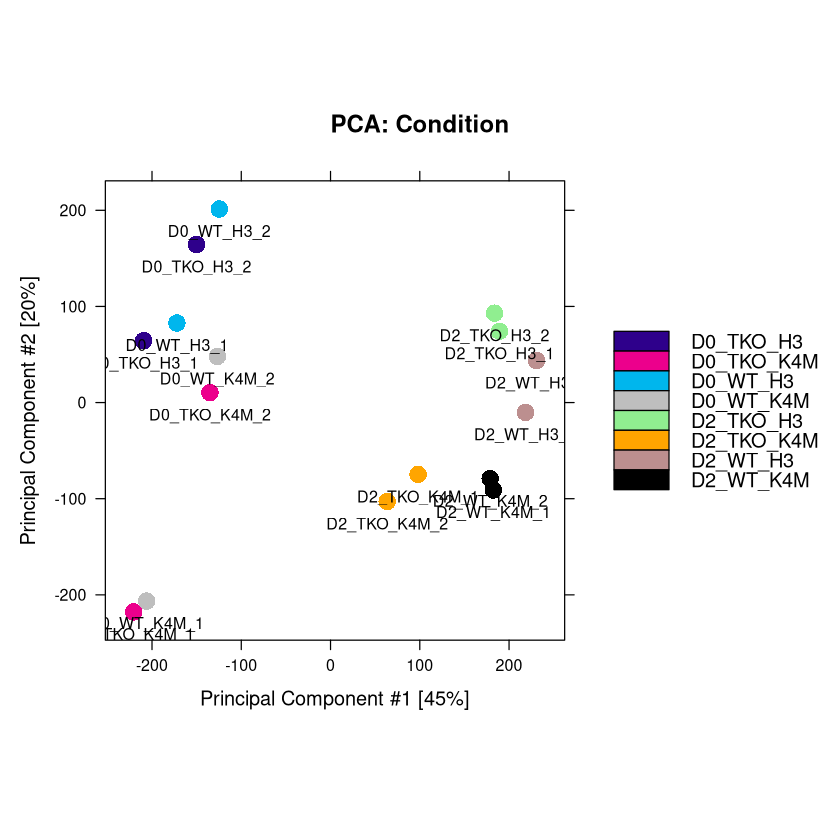

In [6]:
dba.plotPCA(atac_db, DBA_CONDITION, label=DBA_ID)


# WT D0 H3 vs WT D0 K4M 

In [ ]:
# define contrast
D0_db_H3_WT_vs_K4M_WT <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D0_WT_K4M", "D0_WT_H3"),
  minMembers = 2
)
D0_db_H3_WT_vs_K4M_WT <- dba.normalize(D0_db_H3_WT_vs_K4M_WT, spikein = TRUE)
D0_db_H3_WT_vs_K4M_WT <- dba.analyze(D0_db_H3_WT_vs_K4M_WT)
dba.show(D0_db_H3_WT_vs_K4M_WT, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1160 of 43954 intervals.

Re-normalizing...

Removed 1160 (of 43954) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D0_WT_K4M,2,D0_WT_H3,2,21910


In [ ]:
#get only the differential peak
diff_peaks_D0_H3_WT_vs_K4M_WT <- dba.report(D0_db_H3_WT_vs_K4M_WT, th = 0.05)
length(diff_peaks_D0_H3_WT_vs_K4M_WT)
head(diff_peaks_D0_H3_WT_vs_K4M_WT)
diff_peaks_D0_H3_WT_vs_K4M_WT <- as.data.frame(diff_peaks_D0_H3_WT_vs_K4M_WT)

[1] 21910

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D0_WT_K4M
           <Rle>           <IRanges>  <Rle> | <numeric>      <numeric>
   3302    chr10   60811335-60815276      * |   8.78408        6.67733
  35776     chr7   68275539-68277349      * |   8.35276        6.33478
   1648     chr1 136231370-136234880      * |   9.20299        7.81920
  36702     chr7 126225811-126229272      * |   7.76225        5.49755
  21350     chr2   29628385-29632254      * |   8.27581        6.58877
  12174    chr14   48664887-48667202      * |   7.86234        5.83551
        Conc_D0_WT_H3      Fold     p-value         FDR
            <numeric> <numeric>   <numeric>   <numeric>
   3302       9.60606  -2.83611 4.71281e-17 2.01680e-12
  35776       9.16266  -2.74069 4.67673e-13 1.00068e-08
   1648       9.89613  -2.01347 8.33040e-13 1.09109e-08
  36702       8.60375  -2.96653 1.44855e-12 1.09109e-08
  21350       9.03235  -2.37984 1.47554e-12

In [5]:
summary(diff_peaks_D0_H3_WT_vs_K4M_WT$Fold)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 -3.891  -1.965  -1.622  -1.623  -1.230   2.761 

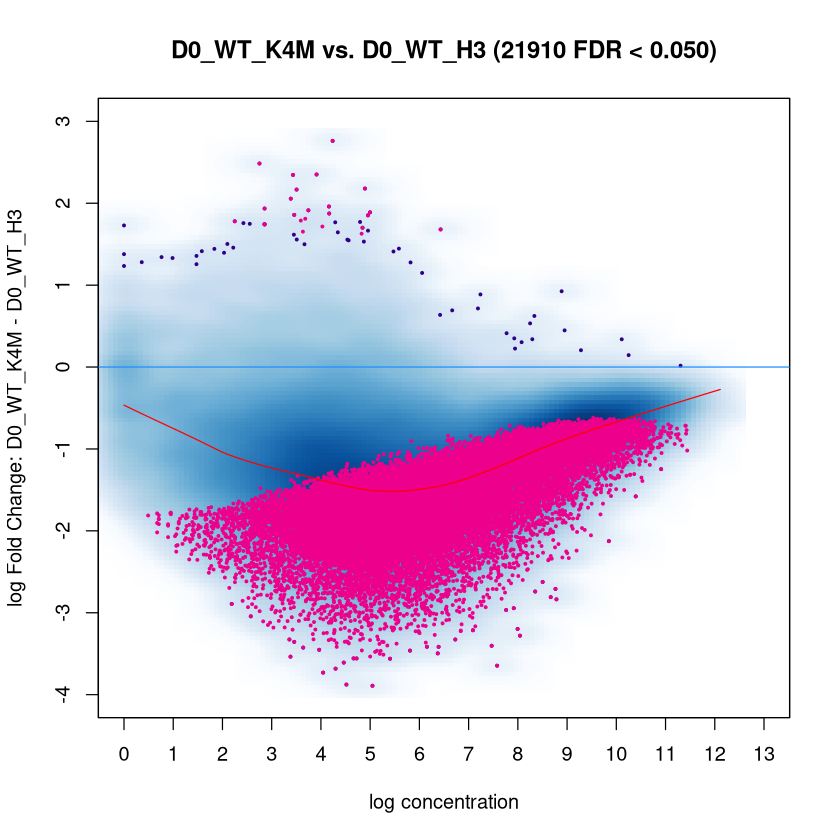

In [7]:
dba.plotMA(D0_db_H3_WT_vs_K4M_WT)

In [9]:
pdf("Volcanoplot_diffbind_H3K4me3/D0_H3_WT_vs_K4M_WT.pdf", width = 8, height = 6)
dba.plotVolcano(D0_db_H3_WT_vs_K4M_WT, contrast=1) 
dev.off()

png 
  2

In [ ]:
#get the list of up and down peaks
setwd("/scratch/Narjesse/scripts/H3K4me3/Diffbind_Spikein/bed_diffbind_H3K4me3_spikein")
D0_WT_H3_enrich <- diff_peaks_D0_H3_WT_vs_K4M_WT %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D0_WT_H3_enrich, file="D0_WT_H3_enriched_D0_H3_WT_vs_D0_K4M_WT.bed", sep="\t", quote=F, row.names=F, col.names=F)

D0_WT_K4M_enrich <- diff_peaks_D0_H3_WT_vs_K4M_WT %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D0_WT_K4M_enrich, file="D0_WT_K4M_enriched_D0_H3_WT_vs_D0_K4M_WT.bed", sep="\t", quote=F, row.names=F, col.names=F)


Attaching package: ‘dplyr’


The following object is masked from ‘package:AnnotationDbi’:

    select


The following object is masked from ‘package:Biobase’:

    combine


The following object is masked from ‘package:matrixStats’:

    count


The following objects are masked from ‘package:GenomicRanges’:

    intersect, setdiff, union


The following object is masked from ‘package:Seqinfo’:

    intersect


The following objects are masked from ‘package:IRanges’:

    collapse, desc, intersect, setdiff, slice, union


The following objects are masked from ‘package:S4Vectors’:

    first, intersect, rename, setdiff, setequal, union


The following objects are masked from ‘package:BiocGenerics’:

    combine, intersect, setdiff, setequal, union


The following object is masked from ‘package:generics’:

    explain


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The foll

In [9]:
cat("number of DO WT H3 enriched peaks :", nrow(D0_WT_H3_enrich),"\n")

number of DO WT H3 enriched peaks : 21886 


In [10]:
cat("number of D0_WT_K4M_enrich peaks :", nrow(D0_WT_K4M_enrich))

number of D0_WT_K4M_enrich peaks : 24

# WT D2 H3 vs WT D2 K4M 


In [10]:
D2_db_H3_WT_vs_K4M_WT <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D2_WT_K4M", "D2_WT_H3"),
  minMembers = 2
)
D2_db_H3_WT_vs_K4M_WT <- dba.normalize(D2_db_H3_WT_vs_K4M_WT, spikein = TRUE)
D2_db_H3_WT_vs_K4M_WT <- dba.analyze(D2_db_H3_WT_vs_K4M_WT)
dba.show(D2_db_H3_WT_vs_K4M_WT, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1160 of 43954 intervals.

Re-normalizing...

Removed 1160 (of 43954) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D2_WT_K4M,2,D2_WT_H3,2,205


In [13]:
df <- dba.report(D2_db_H3_WT_vs_K4M_WT,th = 1, DataType = DBA_DATA_FRAME)
write.table(df, file="Comparaison_diffbind_spikein_H3K4me3/H3K4me3_all_D0_H3_WT_vs_D2_K4M_WT.bed", sep="\t", quote=F, row.names=F, col.names=TRUE)


Warning message in file(file, ifelse(append, "a", "w")):
“cannot open file 'Comparaison_diffbind_spikein_H3K4me3/H3K4me3_all_D0_H3_WT_vs_D2_K4M_WT.bed': No such file or directory”


ERROR: Error in file(file, ifelse(append, "a", "w")): cannot open the connection


In [14]:
head(df)
nrow(df)

,Chr,Start,End,Conc,Conc_D2_WT_K4M,Conc_D2_WT_H3,Fold,p-value,FDR
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
29748,chr5,44798496,44800229,6.693458,4.184275,7.560836,-2.271624,6.902633e-10,2.553008e-05
18380,chr18,6773350,6774948,5.680715,3.640691,6.493698,-2.016335,1.348770e-08,2.494281e-04
30210,chr5,92698116,92699509,5.588316,3.625035,6.390349,-1.935926,5.347742e-08,5.303140e-04
1284,chr1,119485541,119488392,6.068355,3.664056,6.925220,-2.046824,5.768256e-08,5.303140e-04
8161,chr11,121517945,121520661,5.678671,3.765672,6.473158,-1.913290,7.169118e-08,5.303140e-04
3302,chr10,60811335,60815276,9.192538,8.096134,9.808255,-1.436339,2.452760e-07,1.511963e-03


[1] 42794

In [15]:
diff_peaks_D2_H3_WT_vs_K4M_WT <- dba.report(D2_db_H3_WT_vs_K4M_WT, th = 0.05)
length(diff_peaks_D2_H3_WT_vs_K4M_WT)
head(diff_peaks_D2_H3_WT_vs_K4M_WT)
diff_peaks_D2_H3_WT_vs_K4M_WT <- as.data.frame(diff_peaks_D2_H3_WT_vs_K4M_WT)

[1] 205

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D2_WT_K4M
           <Rle>           <IRanges>  <Rle> | <numeric>      <numeric>
  29748     chr5   44798496-44800229      * |   6.69346        4.18428
  18380    chr18     6773350-6774948      * |   5.68072        3.64069
  30210     chr5   92698116-92699509      * |   5.58832        3.62504
   1284     chr1 119485541-119488392      * |   6.06835        3.66406
   8161    chr11 121517945-121520661      * |   5.67867        3.76567
   3302    chr10   60811335-60815276      * |   9.19254        8.09613
        Conc_D2_WT_H3      Fold     p-value         FDR
            <numeric> <numeric>   <numeric>   <numeric>
  29748       7.56084  -2.27162 6.90263e-10 2.55301e-05
  18380       6.49370  -2.01633 1.34877e-08 2.49428e-04
  30210       6.39035  -1.93593 5.34774e-08 5.30314e-04
   1284       6.92522  -2.04682 5.76826e-08 5.30314e-04
   8161       6.47316  -1.91329 7.16912e-08

In [16]:
summary(diff_peaks_D2_H3_WT_vs_K4M_WT$Fold)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 -2.272  -1.466  -1.366  -1.366  -1.292   1.463 

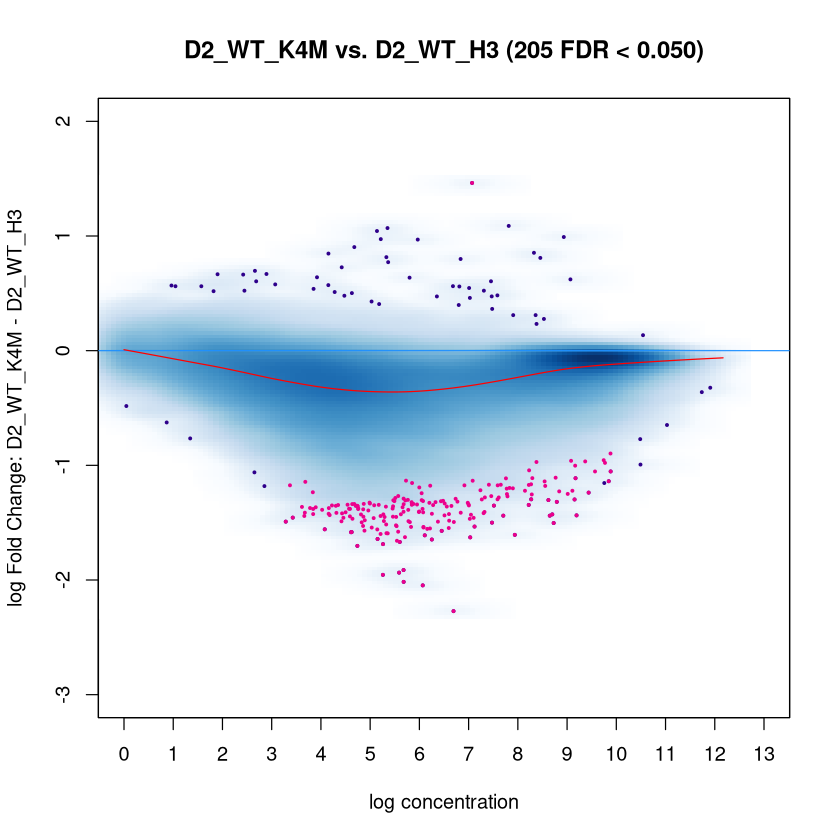

In [17]:
dba.plotMA(D2_db_H3_WT_vs_K4M_WT)

In [18]:
pdf("Volcanoplot_diffbind_H3K4me3/D2_H3_WT_vs_K4M_WT.pdf", width = 8, height = 6)
dba.plotVolcano(D2_db_H3_WT_vs_K4M_WT, contrast=1) 
dev.off()

png 
  2

In [ ]:
setwd("/scratch/Narjesse/scripts/H3K4me3/Diffbind_Spikein/bed_diffbind_H3K4me3_spikein")
D2_WT_H3_enrich <- diff_peaks_D2_H3_WT_vs_K4M_WT %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end,Fold)
# Write to file
write.table(D2_WT_H3_enrich, file="H3K4me3_D2_WT_H3_enriched_D2_H3_WT_vs_D2_K4M_WT.bed", sep="\t", quote=F, row.names=F, col.names=F)

D2_WT_K4M_enrich <- diff_peaks_D2_H3_WT_vs_K4M_WT %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D2_WT_K4M_enrich, file="D2_WT_K4M_enriched_D2_H3_WT_vs_D2_K4M_WT.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [19]:
cat("number of D2 WT H3 enriched peaks :", nrow(D2_WT_H3_enrich),"\n")

number of D2 WT H3 enriched peaks : 204 


In [20]:
cat("number of D2_WT_K4M_enrich peaks :", nrow(D2_WT_K4M_enrich))

number of D2_WT_K4M_enrich peaks : 1

# D0 TKO H3 vs D0 TKO K4M


In [19]:
D0_db_H3_TKO_vs_K4M_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D0_TKO_K4M", "D0_TKO_H3"),
  minMembers = 2
)
D0_db_H3_TKO_vs_K4M_TKO <- dba.normalize(D0_db_H3_TKO_vs_K4M_TKO,spikein = TRUE)
D0_db_H3_TKO_vs_K4M_TKO <- dba.analyze(D0_db_H3_TKO_vs_K4M_TKO)
dba.show(D0_db_H3_TKO_vs_K4M_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1160 of 43954 intervals.

Re-normalizing...

Removed 1160 (of 43954) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D0_TKO_K4M,2,D0_TKO_H3,2,1794


In [20]:
diff_peaks_D0_H3_TKO_vs_K4M_TKO <- dba.report(D0_db_H3_TKO_vs_K4M_TKO, th = 0.05)
length(diff_peaks_D0_H3_TKO_vs_K4M_TKO)
head(diff_peaks_D0_H3_TKO_vs_K4M_TKO)
diff_peaks_D0_H3_TKO_vs_K4M_TKO <- as.data.frame(diff_peaks_D0_H3_TKO_vs_K4M_TKO)

[1] 1794

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D0_TKO_K4M
           <Rle>           <IRanges>  <Rle> | <numeric>       <numeric>
   3302    chr10   60811335-60815276      * |   8.38855         7.03764
  28136     chr4 133439751-133443620      * |   8.12788         6.36901
   9524    chr12 106173095-106177109      * |   6.85483         4.14137
   1648     chr1 136231370-136234880      * |   8.44299         7.32054
  31975     chr5 147760983-147762719      * |   5.64638         2.31248
  25444     chr3 103127203-103132207      * |   7.63088         5.77079
        Conc_D0_TKO_H3      Fold     p-value         FDR
             <numeric> <numeric>   <numeric>   <numeric>
   3302        9.07378  -1.90563 1.23333e-09 5.07319e-05
  28136        8.89724  -2.16374 3.42459e-09 7.04335e-05
   9524        7.74043  -2.54875 7.94095e-09 8.22433e-05
   1648        9.06656  -1.57103 7.99760e-09 8.22433e-05
  31975        6.57300  -2.83

In [21]:
summary(diff_peaks_D0_H3_TKO_vs_K4M_TKO$Fold)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 -2.853  -1.696  -1.506  -1.491  -1.357   1.868 

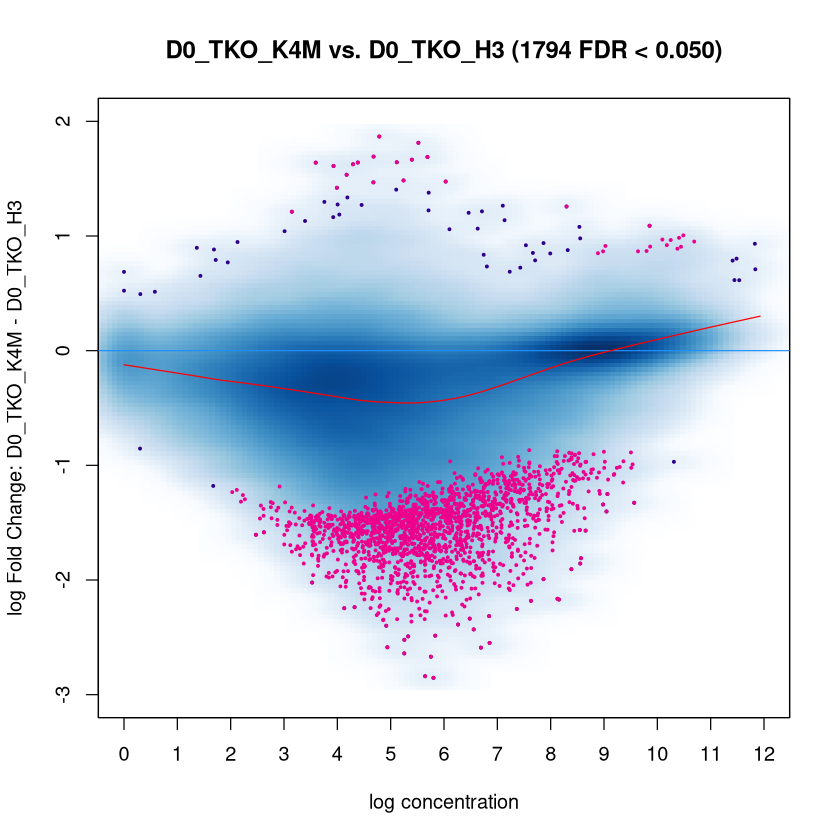

In [24]:
dba.plotMA(D0_db_H3_TKO_vs_K4M_TKO)

png 
  2

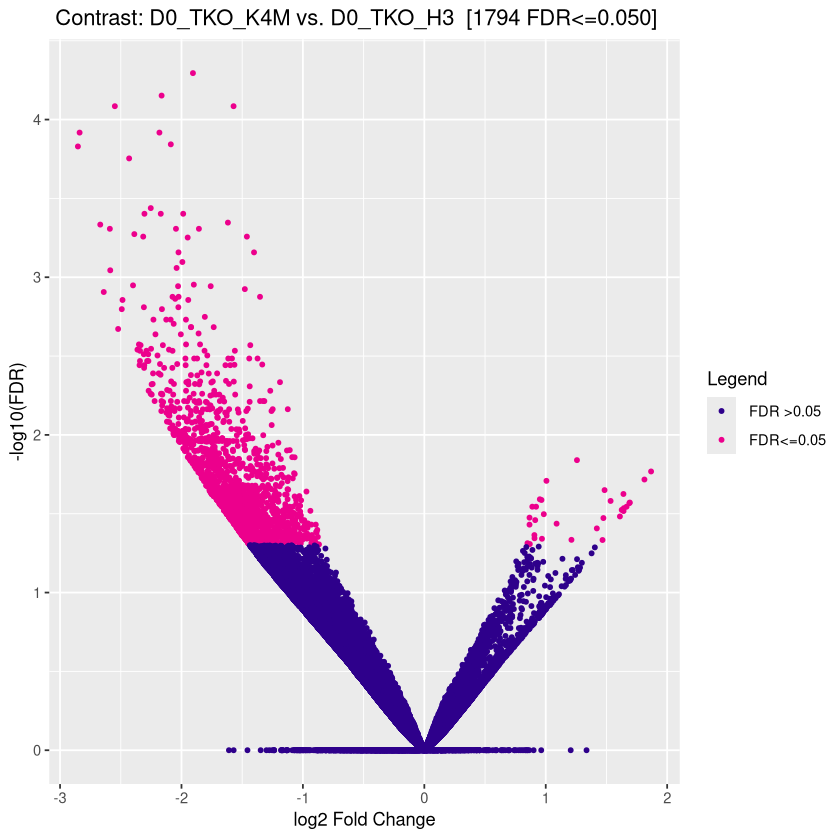

In [22]:
dba.plotVolcano(D0_db_H3_TKO_vs_K4M_TKO, contrast=1)
pdf("Volcanoplot_diffbind_H3K4me3/D0_H3_TKO_vs_K4M_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D0_db_H3_TKO_vs_K4M_TKO, contrast=1)
dev.off()

In [26]:
setwd("/scratch/Narjesse/scripts/H3K4me3/Diffbind_Spikein/bed_diffbind_H3K4me3_spikein")
D0_TKO_H3_enrich <- diff_peaks_D0_H3_TKO_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D0_TKO_H3_enrich, file="D0_TKO_H3_enriched_D0_H3_TKO_vs_D0_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

D0_TKO_K4M_enrich <- diff_peaks_D0_H3_TKO_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D0_TKO_K4M_enrich, file="D0_TKO_K4M_enriched__D0_H3_TKO_vs_D0_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [27]:
cat("number of D0_TKO_H3_enrich peaks :", nrow(D0_TKO_H3_enrich),"\n")

number of D0_TKO_H3_enrich peaks : 1762 


In [28]:
cat("number of D0_TKO_K4M_enrich peaks :", nrow(D0_TKO_K4M_enrich))

number of D0_TKO_K4M_enrich peaks : 32

### D2 TKO H3 VS D2 TKO K4M

In [23]:
D2_db_H3_TKO_vs_K4M_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D2_TKO_K4M", "D2_TKO_H3"),
  minMembers = 2
)
D2_db_H3_TKO_vs_K4M_TKO <- dba.normalize(D2_db_H3_TKO_vs_K4M_TKO, spikein = TRUE)
D2_db_H3_TKO_vs_K4M_TKO <- dba.analyze(D2_db_H3_TKO_vs_K4M_TKO)
dba.show(D2_db_H3_TKO_vs_K4M_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1160 of 43954 intervals.

Re-normalizing...

Removed 1160 (of 43954) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D2_TKO_K4M,2,D2_TKO_H3,2,27772


In [11]:
df <- dba.report(D2_db_H3_TKO_vs_K4M_TKO,th = 1, DataType = DBA_DATA_FRAME)
write.table(df, file="Comparaison_diffbind_spikein_H3K4me3/H3K4me3_all_D2_H3_TKO_vs_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=TRUE)


In [4]:
diff_peaks_D2_H3_TKO_vs_K4M_TKO <- dba.report(D2_db_H3_TKO_vs_K4M_TKO, th = 0.05)
length(diff_peaks_D2_H3_TKO_vs_K4M_TKO)
head(diff_peaks_D2_H3_TKO_vs_K4M_TKO)
diff_peaks_D2_H3_TKO_vs_K4M_TKO <- as.data.frame(diff_peaks_D2_H3_TKO_vs_K4M_TKO)

[1] 27772

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D2_TKO_K4M
           <Rle>           <IRanges>  <Rle> | <numeric>       <numeric>
   3302    chr10   60811335-60815276      * |   8.88155         6.76197
   7754    chr11 115171359-115174949      * |   8.48386         6.33824
   1648     chr1 136231370-136234880      * |   9.57562         7.98916
   9588    chr12 109525896-109531153      * |   9.62667         7.89767
  33963     chr6 126162321-126167322      * |   9.01656         6.58131
  25086     chr3   89225483-89228989      * |   9.46904         7.90179
        Conc_D2_TKO_H3      Fold     p-value         FDR
             <numeric> <numeric>   <numeric>   <numeric>
   3302        9.70521  -2.84245 3.99228e-18 1.70846e-13
   7754        9.31087  -2.86667 1.07187e-17 2.29348e-13
   1648       10.31289  -2.26889 1.51259e-16 1.83941e-12
   9588       10.39079  -2.42432 1.71932e-16 1.83941e-12
  33963        9.87661  -3.13

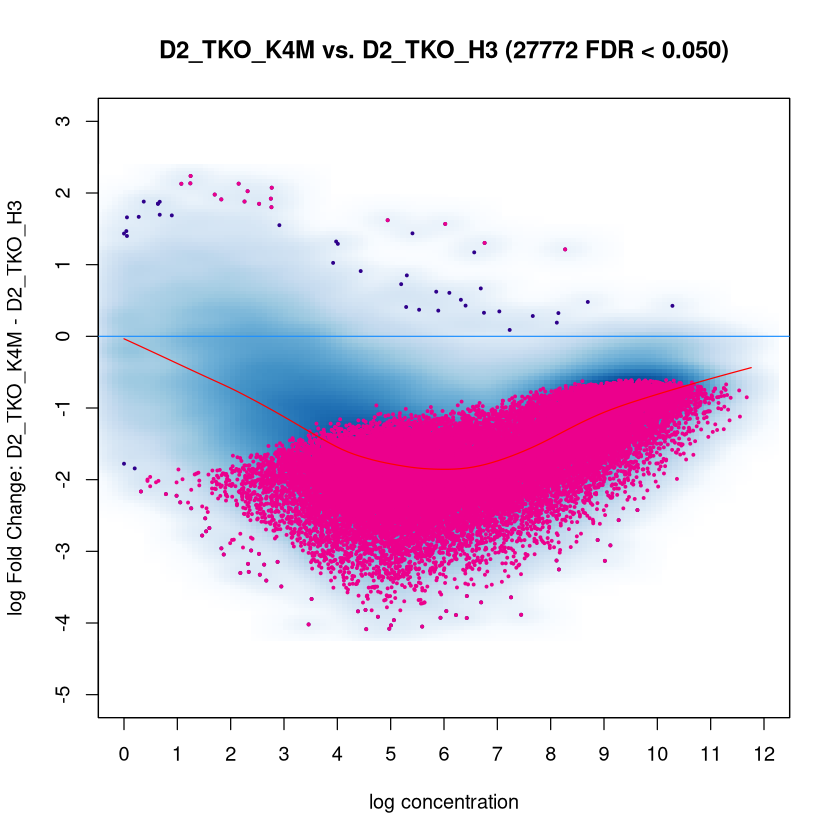

In [5]:
dba.plotMA(D2_db_H3_TKO_vs_K4M_TKO)

In [24]:
pdf("Volcanoplot_diffbind_H3K4me3/D2_H3_TKO_vs_K4M_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D2_db_H3_TKO_vs_K4M_TKO, contrast=1)
dev.off()

png 
  2

In [ ]:
setwd("/scratch/Narjesse/scripts/H3K4me3/Diffbind_Spikein/bed_diffbind_H3K4me3_spikein")
D2_TKO_H3_enrich <- diff_peaks_D2_H3_TKO_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end,Fold,FDR)

# Write to file
write.table(D2_TKO_H3_enrich, file="D2_TKO_H3_enriched_D2_H3_TKO_vs_D2_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

D2_TKO_K4M_enrich <- diff_peaks_D2_H3_TKO_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>%
  dplyr::select(seqnames, start, end,Fold,FDR)


# Write to file
write.table(D2_TKO_K4M_enrich, file="D2_TKO_K4M_enriched__D2_H3_TKO_vs_D2_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [12]:
cat("number of D2_TKO_H3_enrich peaks :", nrow(D2_TKO_H3_enrich),"\n")

number of D2_TKO_H3_enrich peaks : 27756 


In [13]:
cat("number of D2_TKO_K4M_enrich peaks :", nrow(D2_TKO_K4M_enrich))

number of D2_TKO_K4M_enrich peaks : 16

### D0 WT H3 vs  TKO H3 

In [25]:
D0_db_H3_WT_vs_H3_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D0_TKO_H3", "D0_WT_H3"),
  minMembers = 2
)
D0_db_H3_WT_vs_H3_TKO <- dba.normalize(D0_db_H3_WT_vs_H3_TKO,spikein = TRUE )
D0_db_H3_WT_vs_H3_TKO <- dba.analyze(D0_db_H3_WT_vs_H3_TKO)
dba.show(D0_db_H3_WT_vs_H3_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1160 of 43954 intervals.

Re-normalizing...

Removed 1160 (of 43954) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D0_TKO_H3,2,D0_WT_H3,2,3068


In [26]:
diff_peaks_D0_H3_WT_vs_H3_TKO <- dba.report(D0_db_H3_WT_vs_H3_TKO, th = 0.05)
length(diff_peaks_D0_H3_WT_vs_H3_TKO)
head(diff_peaks_D0_H3_WT_vs_H3_TKO)
diff_peaks_D0_H3_WT_vs_H3_TKO <- as.data.frame(diff_peaks_D0_H3_WT_vs_H3_TKO)


[1] 3068

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D0_TKO_H3
           <Rle>           <IRanges>  <Rle> | <numeric>      <numeric>
  20731    chr19   48204190-48207117      * |   7.35621        5.54498
   9540    chr12 108001926-108006524      * |   8.70475        7.26405
  12917    chr14 100283312-100286787      * |  10.88664        9.52936
  14580    chr15   97764945-97768566      * |   8.30479        6.85240
   3721    chr10   77901673-77903580      * |   9.08206        7.75188
  13195    chr15     8709229-8710975      * |   7.17536        5.45794
        Conc_D0_WT_H3      Fold     p-value         FDR
            <numeric> <numeric>   <numeric>   <numeric>
  20731       8.13446  -1.86667 4.37940e-10 8.93091e-06
   9540       9.41105  -1.68919 9.62553e-10 9.81467e-06
  12917      11.57342  -1.61357 3.32582e-09 1.80676e-05
  14580       9.01371  -1.65378 3.54388e-09 1.80676e-05
   3721       9.76218  -1.58307 5.35456e-09

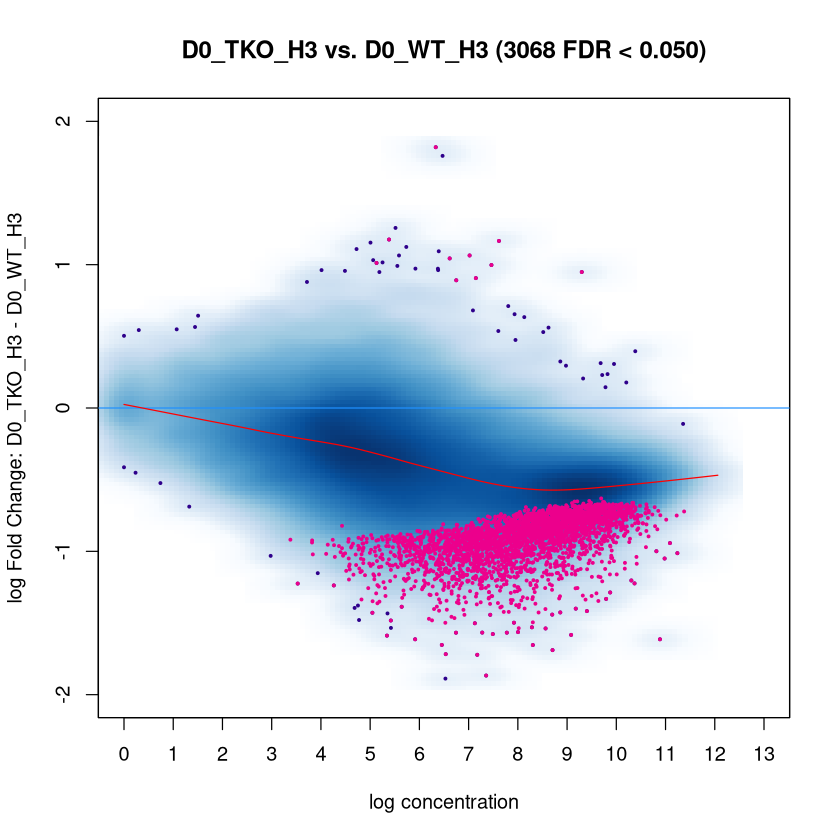

In [27]:
dba.plotMA(D0_db_H3_WT_vs_H3_TKO)

In [29]:
pdf("Volcanoplot_diffbind_H3K4me3/D0_H3_WT_vs_H3_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D0_db_H3_WT_vs_H3_TKO, contrast=1)
dev.off()

png 
  2

In [33]:
setwd("/scratch/Narjesse/scripts/H3K4me3/Diffbind_Spikein/bed_diffbind_H3K4me3_spikein")

D0_WT_H3_enrich <- diff_peaks_D0_H3_WT_vs_H3_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D0_WT_H3_enrich, file="D0_WT_H3_enriched_D0_H3_WT_vs_D0_H3_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

D0_TKO_H3_enrich <- diff_peaks_D0_H3_WT_vs_H3_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D0_TKO_H3_enrich, file="D0_TKO_H3_enriched_D0_H3_WT_vs_D0_H3_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [34]:
cat("number of D0_TKO_H3_enrich peaks :", nrow(D0_TKO_H3_enrich),"\n")

number of D0_TKO_H3_enrich peaks : 10 


In [35]:
cat("number of D0_WT_H3_enrich peaks :", nrow(D0_WT_H3_enrich))

number of D0_WT_H3_enrich peaks : 3058

### D2 WT H3 vs  TKO H3 


In [30]:
D2_db_H3_WT_vs_H3_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D2_TKO_H3", "D2_WT_H3"),
  minMembers = 2
)
D2_db_H3_WT_vs_H3_TKO <- dba.normalize(D2_db_H3_WT_vs_H3_TKO, spikein = TRUE)
D2_db_H3_WT_vs_H3_TKO <- dba.analyze(D2_db_H3_WT_vs_H3_TKO)
dba.show(D2_db_H3_WT_vs_H3_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1160 of 43954 intervals.

Re-normalizing...

Removed 1160 (of 43954) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D2_TKO_H3,2,D2_WT_H3,2,289


In [32]:
df <- dba.report(D2_db_H3_WT_vs_H3_TKO,th = 1, DataType = DBA_DATA_FRAME)
write.table(df, file="Comparaison_diffbind_spikein_H3K4me3/H3K4me3_all_D2_H3_WT_vs_H3_TKO.bed", sep="\t", quote=F, row.names=F, col.names=TRUE)


Warning message in file(file, ifelse(append, "a", "w")):
“cannot open file 'Comparaison_diffbind_spikein_H3K4me3/H3K4me3_all_D2_H3_WT_vs_H3_TKO.bed': No such file or directory”


ERROR: Error in file(file, ifelse(append, "a", "w")): cannot open the connection


In [33]:
diff_peaks_D2_H3_WT_vs_H3_TKO <- dba.report(D2_db_H3_WT_vs_H3_TKO, th = 0.05)
length(diff_peaks_D2_H3_WT_vs_H3_TKO)
head(diff_peaks_D2_H3_WT_vs_H3_TKO)
diff_peaks_D2_H3_WT_vs_H3_TKO <- as.data.frame(diff_peaks_D2_H3_WT_vs_H3_TKO)

[1] 289

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D2_TKO_H3
           <Rle>           <IRanges>  <Rle> | <numeric>      <numeric>
  13783    chr15   72809046-72811035      * |   8.22167        9.18228
   1027     chr1   87675845-87680363      * |   8.39144        9.11086
  26779     chr4   57844997-57847433      * |   6.44539        7.21892
  33662     chr6 115729708-115733152      * |   8.50627        9.26899
  21483     chr2   31452991-31455871      * |   7.93899        8.68025
   9575    chr12 109032833-109034568      * |   7.81399        5.47730
        Conc_D2_WT_H3      Fold     p-value         FDR
            <numeric> <numeric>   <numeric>   <numeric>
  13783       4.00711   4.67160 8.84705e-25 3.78601e-20
   1027       6.89118   2.09739 4.52240e-09 9.67657e-05
  26779       4.66224   2.33778 2.95668e-08 3.19000e-04
  33662       6.78516   2.28825 3.40162e-08 3.19000e-04
  21483       6.33240   2.18086 3.72716e-08

Warning message in KernSmooth::bkde2D(x, bandwidth = bandwidth, gridsize = nbin, :
“Binning grid too coarse for current (small) bandwidth: consider increasing 'gridsize'”


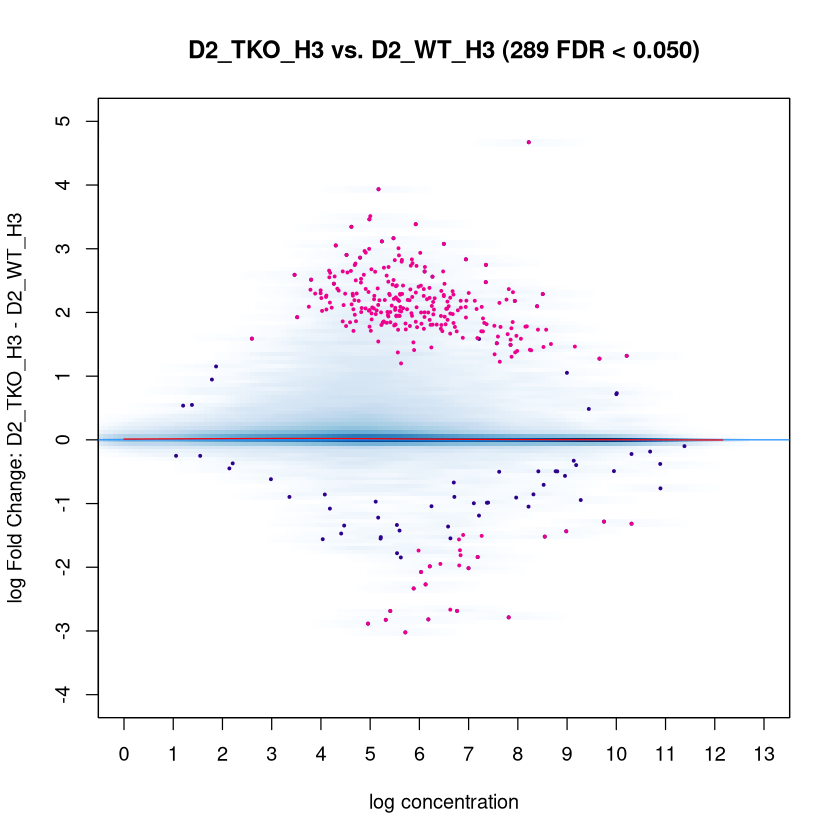

In [34]:
dba.plotMA(D2_db_H3_WT_vs_H3_TKO)


In [36]:
pdf("Volcanoplot_diffbind_H3K4me3/D2_H3_WT_vs_H3_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D2_db_H3_WT_vs_H3_TKO, contrast=1)
dev.off()

png 
  2

In [ ]:
setwd("/scratch/Narjesse/scripts/H3K4me3/Diffbind_Spikein/bed_diffbind_H3K4me3_spikein")
D2_WT_H3_enrich <- diff_peaks_D2_H3_WT_vs_H3_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D2_WT_H3_enrich, file="D2_WT_H3_enriched_D2_H3_WT_vs_D2_H3_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

D2_TKO_H3_enrich <- diff_peaks_D2_H3_WT_vs_H3_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D2_TKO_H3_enrich, file="D2_TKO_H3_enriched_D2_H3_WT_vs_D2_H3_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [41]:
cat("number of D2_TKO_H3_enrich peaks :", nrow(D2_TKO_H3_enrich),"\n")

number of D2_TKO_H3_enrich peaks : 263 


In [42]:
cat("number of D2_WT_H3_enrich peaks :", nrow(D2_WT_H3_enrich))


number of D2_WT_H3_enrich peaks : 26

### D0 WT K4M vs  TKO K4M


In [37]:
D0_db_K4M_WT_vs_K4M_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D0_TKO_K4M", "D0_WT_K4M"),
  minMembers = 2
)
D0_db_K4M_WT_vs_K4M_TKO <- dba.normalize(D0_db_K4M_WT_vs_K4M_TKO,spikein = TRUE)
D0_db_K4M_WT_vs_K4M_TKO <- dba.analyze(D0_db_K4M_WT_vs_K4M_TKO)
dba.show(D0_db_K4M_WT_vs_K4M_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1160 of 43954 intervals.

Re-normalizing...

Removed 1160 (of 43954) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D0_TKO_K4M,2,D0_WT_K4M,2,97


In [38]:
diff_peaks_K4M_WT_vs_K4M_TKO <- dba.report(D0_db_K4M_WT_vs_K4M_TKO, th = 0.05)
length(diff_peaks_K4M_WT_vs_K4M_TKO)
head(diff_peaks_K4M_WT_vs_K4M_TKO)
diff_peaks_K4M_WT_vs_K4M_TKO <- as.data.frame(diff_peaks_K4M_WT_vs_K4M_TKO)

[1] 97

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D0_TKO_K4M
           <Rle>           <IRanges>  <Rle> | <numeric>       <numeric>
  38915     chr8 106510438-106512218      * |   8.19515         8.92329
  39448     chr8 124374047-124376771      * |   6.69218         7.63931
  13783    chr15   72809046-72811035      * |   5.36923         6.27345
   3721    chr10   77901673-77903580      * |   8.36004         7.12838
  39521     chr8 125994747-125997525      * |   7.08646         7.86962
   4139    chr10   88682426-88685268      * |   6.67874         7.49062
        Conc_D0_WT_K4M      Fold     p-value         FDR
             <numeric> <numeric>   <numeric>   <numeric>
  38915        6.65351   2.10674 1.45848e-10 5.75735e-06
  39448        2.89580   3.07698 2.61977e-09 4.22500e-05
  13783        2.40869   2.81800 3.21089e-09 4.22500e-05
   3721        9.01463  -1.67590 1.25914e-07 1.24261e-03
  39521        5.24531   2.02

Warning message in KernSmooth::bkde2D(x, bandwidth = bandwidth, gridsize = nbin, :
“Binning grid too coarse for current (small) bandwidth: consider increasing 'gridsize'”


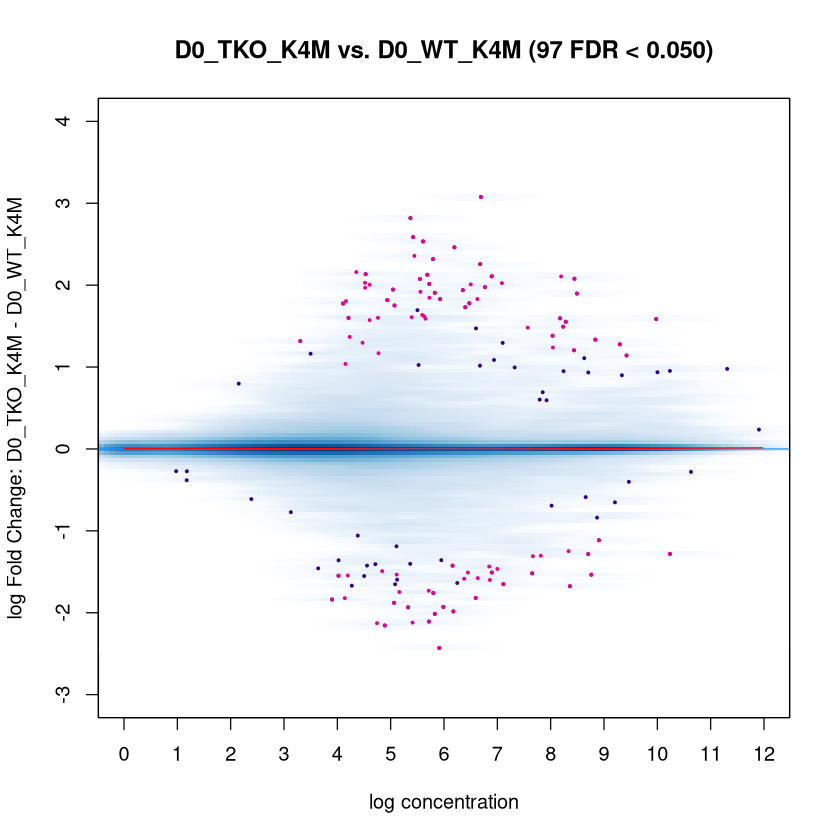

In [39]:
dba.plotMA(D0_db_K4M_WT_vs_K4M_TKO)

In [41]:
pdf("Volcanoplot_diffbind_H3K4me3/D0_K4M_WT_vs_K4M_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D0_db_K4M_WT_vs_K4M_TKO, contrast=1)
dev.off()

png 
  2

In [8]:
setwd("/scratch/Narjesse/scripts/H3K4me3/Diffbind_Spikein/bed_diffbind_H3K4me3_spikein")
library(dplyr)
D0_WT_K4M_enrich <- diff_peaks_K4M_WT_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D0_WT_K4M_enrich, file="D0_WT_K4M_enriched_D0_K4M_WT_vs_D0_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

D0_TKO_K4M_enrich <- diff_peaks_K4M_WT_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D0_TKO_K4M_enrich, file="D0_TKO_K4M_enriched_D0_K4M_WT_vs_D0_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)


Attaching package: ‘dplyr’


The following object is masked from ‘package:AnnotationDbi’:

    select


The following object is masked from ‘package:Biobase’:

    combine


The following object is masked from ‘package:matrixStats’:

    count


The following objects are masked from ‘package:GenomicRanges’:

    intersect, setdiff, union


The following object is masked from ‘package:Seqinfo’:

    intersect


The following objects are masked from ‘package:IRanges’:

    collapse, desc, intersect, setdiff, slice, union


The following objects are masked from ‘package:S4Vectors’:

    first, intersect, rename, setdiff, setequal, union


The following objects are masked from ‘package:BiocGenerics’:

    combine, intersect, setdiff, setequal, union


The following object is masked from ‘package:generics’:

    explain


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The foll

In [9]:
cat("number of D0_WT_K4M_enrich peaks :", nrow(D0_WT_K4M_enrich),"\n")

number of D0_WT_K4M_enrich peaks : 38 


In [10]:
cat("number of D0_TKO_K4M_enrich peaks :", nrow(D0_TKO_K4M_enrich),"\n")

number of D0_TKO_K4M_enrich peaks : 59 


### D2 WT K4M vs  TKO K4M


In [42]:
D2_db_K4M_WT_vs_K4M_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D2_TKO_K4M", "D2_WT_K4M"),
  minMembers = 2
)
D2_db_K4M_WT_vs_K4M_TKO <- dba.normalize(D2_db_K4M_WT_vs_K4M_TKO,spikein = TRUE)
D2_db_K4M_WT_vs_K4M_TKO <- dba.analyze(D2_db_K4M_WT_vs_K4M_TKO)
dba.show(D2_db_K4M_WT_vs_K4M_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1160 of 43954 intervals.

Re-normalizing...

Removed 1160 (of 43954) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D2_TKO_K4M,2,D2_WT_K4M,2,4251


In [15]:
df <- dba.report(D2_db_K4M_WT_vs_K4M_TKO,th = 1, DataType = DBA_DATA_FRAME)
write.table(df, file="Comparaison_diffbind_spikein_H3K4me3/H3K4me3_all_D2_K4M_WT_vs_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=TRUE)


In [12]:
diff_peaks_D2_K4M_WT_vs_K4M_TKO <- dba.report(D2_db_K4M_WT_vs_K4M_TKO, th = 0.05)
length(diff_peaks_D2_K4M_WT_vs_K4M_TKO)
head(diff_peaks_D2_K4M_WT_vs_K4M_TKO)
diff_peaks_D2_K4M_WT_vs_K4M_TKO <- as.data.frame(diff_peaks_D2_K4M_WT_vs_K4M_TKO)

[1] 4251

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D2_TKO_K4M
           <Rle>           <IRanges>  <Rle> | <numeric>       <numeric>
  24079     chr2 174283701-174288134      * |   8.73827         6.93670
   1027     chr1   87675845-87680363      * |   7.04090         7.86699
  13783    chr15   72809046-72811035      * |   6.27029         7.16584
  10299    chr13   42708904-42710614      * |   7.05593         4.07149
   9540    chr12 108001926-108006524      * |   9.36054         7.65722
  35618     chr7   49632376-49640420      * |   8.40875         6.71378
        Conc_D2_WT_K4M      Fold     p-value         FDR
             <numeric> <numeric>   <numeric>   <numeric>
  24079        9.51491  -2.21595 4.31822e-15 1.09558e-10
   1027        4.90249   2.38625 1.17411e-13 1.48942e-09
  13783        3.43046   2.67887 2.35798e-13 1.99414e-09
  10299        7.96178  -2.69830 5.20503e-13 3.30142e-09
   9540       10.12005  -2.08

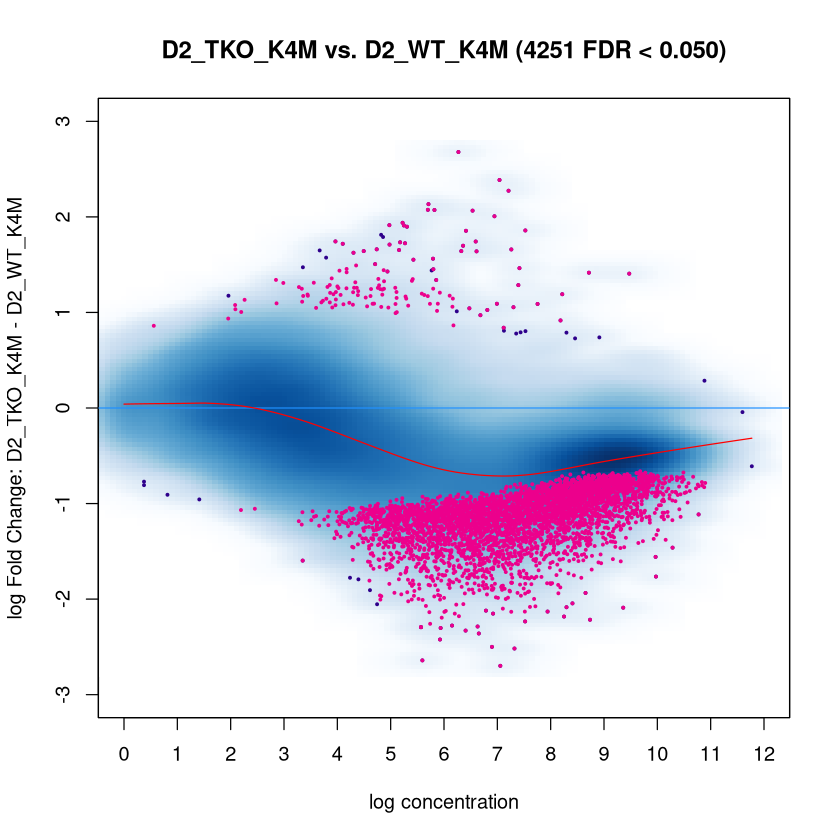

In [13]:
dba.plotMA(D2_db_K4M_WT_vs_K4M_TKO)

In [43]:
pdf("Volcanoplot_diffbind_H3K4me3/D2_K4M_WT_vs_K4M_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D2_db_K4M_WT_vs_K4M_TKO, contrast=1)
dev.off()

png 
  2

In [15]:
setwd("/scratch/Narjesse/scripts/H3K4me3/Diffbind_Spikein/bed_diffbind_H3K4me3_spikein")
library(dplyr)
D2_WT_K4M_enrich <- diff_peaks_D2_K4M_WT_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D2_WT_K4M_enrich, file="D2_WT_K4M_enriched_D2_K4M_WT_vs_D2_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)
D2_TKO_K4M_enrich <- diff_peaks_D2_K4M_WT_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D2_TKO_K4M_enrich, file="D2_TKO_K4M_enriched_D2_K4M_WT_vs_D2_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [16]:
cat("number of D2_WT_K4M_enrich peaks :", nrow(D2_WT_K4M_enrich),"\n")

number of D2_WT_K4M_enrich peaks : 4117 


In [17]:
cat("number of D2_TKO_K4M_enrich peaks :", nrow(D2_TKO_K4M_enrich))

number of D2_TKO_K4M_enrich peaks : 134